In [2]:
import time
import footsiesgym

env = footsiesgym.make(
    platform="mac",
    launch_binaries=False,
    config={
        "port": 50051,
        "headless": False,
        "max_t": 250,
        "action_delay": 0,
        "guard_break_reward": 0.2,
        "use_reward_budget": True,
    },
)

try:
    obs, _ = env.reset()

    for step in range(30):
        distance = obs["p1"][0]
        action = 2 if distance > 0.2 else 3

        obs, rewards, terminated, truncated, infos = env.step({
            "p1": action,
            "p2": 0,
        })

        if step % 5 == 0:
            distance = obs["p1"][0]
            print(
                f"Step {step}: distance={distance:.3f}, reward={rewards['p1']}")

        if any(terminated.values()) or any(truncated.values()):
            break

        time.sleep(0.05)
finally:
    env.close()


Step 0: distance=0.482, reward=0.0
Step 5: distance=0.390, reward=0.0
Step 10: distance=0.298, reward=0.0
Step 15: distance=0.207, reward=0.0
Step 20: distance=0.188, reward=0.0
Step 25: distance=0.229, reward=0.0


### Demo: hardcode policy

In this demo, player 2 will not move, and we hardcode a simple strategy for player 1.
>action = 2 if distance > 0.2 else 3

The reward is set by:
>guard_break_reward: 0.2
>
>use_reward_budget: True (budget is 1)

But we don't want to manually hardcode this.

---

### Idea: value estimation, learn action's value -> pick best action

Let's assume each action has a "value" (Let's say there exists a objective truth for this value). 

If we know that, we can just always picked most vaulable action.

But we don't know an action's value, then what?

Use Monte Carlo(MC) to repeatedly sampling and approximate. ex. MC can be used to approximate pi. 

Temporal difference (TD) combines MC's model free sampling + bootstraping, but let's focus on MC now.


<br>

### Next question: what is, or how to define reward?

Just like dopamine plays an **important** role in motivation, we can play god, and decide what is good or bad by defining a **reward function**.

reward is a biased judgement. It reflects what **we want** the agent to achieve.

Here is a key point:
>Reward tells the agent **what is good**, not necessarily **what to do**.
>
>Like, drug brings lot of pleasure, but we all agree a person should not use drug 24/7.

Here are a few basic terms:
- State: What's the current situation? or observations

- Action: What can the agent do?

- Policy: Given a state, how does the agent choose an action?

- Reward: A numerical feedback signal evaluating what happened.

- Value: from now on, expected cumulative reward.


### Question: how to start?
our policy idea is:
> let's do whatever action can provide the highest reward

But, when the agent starts, there is **nothing**, no knowledge, no reward. So based on our policy, it won't move. 
> Reward requires actions

but we say
> Action needs reward!

So it's a chicken and egg problem and the agent will stuck still.

### Solution: Random!
policy is:
>s -> a

It does not necessarily need to be deterministic. It can output probabilities of actions.

$$
\pi(a \mid s) = P(\text{choose } a \mid s)
$$

In our random policy, it just uses random to determine action.

### Key learning: $b$ and $\pi$ can be separated

The reason we asked "how to start?" is we assume 1 policy do all the work (which it could).

But:
>the policy to interact with environment/collect data (a.k.a Behavior policy $b$)
>
>the policy being learned or evaluated (a.k.a Target policy $\pi$)
>
>**don't have to be the same.**
>
>This is key to understand **on/off policy**.

for example, in the code, we used **epsilon greedy**:
> 90% choose the best action, 10% random
>
> so that it has chance to explore.


---

### How to use reward to adjust action P?

The most naive way is:
>increase the probability of the action that brings reward
>
>while also keep probability sum to **100%**

In [6]:
import random

random.seed(7)

# 2 actions
actions = ["wait", "punch"]

# random chance initially
probs = {"wait": 0.5, "punch": 0.5}

# reward we set
rewards = {"wait": 0, "punch": 1}

alpha = 0.2

for step in range(1, 21):
    action = random.choices(actions, weights=probs.values())[0]
    reward = rewards[action]

    # increase action P while keep sum to 100%
    for a in actions:
        probs[a] *= (1 - alpha * reward)

    probs[action] += alpha * reward

    if step in [1, 5, 10, 20]:
        print(step, action, reward, "punch prob:", round(probs["punch"], 3))

1 wait 0 punch prob: 0.5
5 punch 1 punch prob: 0.68
10 punch 1 punch prob: 0.836
20 punch 1 punch prob: 0.973


### What is the current value of a future reward?

Reward is not always immediate. How to measure a future reward's value now?

You probably heard of the marshmallow test: 1 marshmallow now, or 2 marshmallows sometimes later.

The question is:
> Does 2 **future** marshmallows worth 2 marshmallows now?
>
> Not necessarily! they can worth less because of time!

Another example, in finance:
> Say I promise to give you 100 dollar 1 year later, but you want the money now. How much should you get?
>
> Usually less than 100, because receiving money earlier gives us more opportunities to use or invest it.

<br>
In RL, we use gamma (symbol is):
$
\gamma
$

to control how much we value future rewards now.

>**current value of future reward = future reward * gamma^k** (k is number of steps)

It's for discounting future reward, for various reason (risk, value of time, delayed satisifaction, etc).

Jargons summary:
- Return: Think of Return of Investiment (ROI). We can view the action as an **investiment** for rewards.
- Return: **sampled/realized** cumulative reward.
- Value: **expected** cumulative reward.

Return equation is:

$$
G_t = r_t + \gamma r_{t+1} + \gamma^2 r_{t+2} + \cdots
$$

In [7]:
actions = ["forward", "forward", "punch"]
rewards = [0, 0, 1]

# discount factor
gamma = 0.9

# Return: from this moment onward, what is the total "future" (discounted) reward.
G = 0

credits = []

for reward in reversed(rewards):
    G = reward + gamma * G
    credits.append(G)

print(list(zip(actions, reversed(credits))))

[('forward', 0.81), ('forward', 0.9), ('punch', 1.0)]


### How to estimate reward before game end? (TD intro)

say we have:
>Dance → Forward → Forward → Punch → +1

Eventually we get a reward. But what is the reward at step 1, 2, 3? 

Yes, if we reach the end, MC can use gamma decay to backprop the final reward to each states.

But, let's say we open another game:
>Dance → Forward → Forward → Forward → Forward → ?

See? the game is not over and there is NO reward to backprop. 

Now what? wait until the game ends?

What if the game takes Really long to get you the reward signal?

That's where TD comes in:
> it learns by bootstrapping from its existing value estimates instead of waiting for the ACTUAL reward from environment.
>
> This allows TD to update values before the episode ends.



<br><br>
---

## What is **learning** mean in RL?  
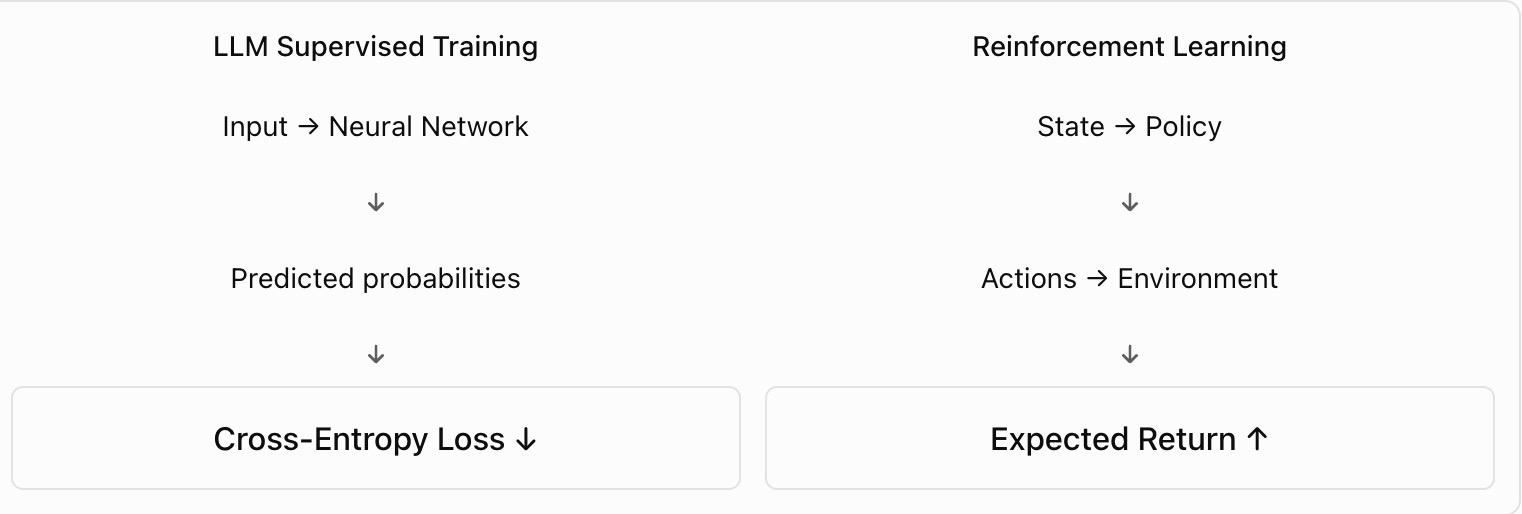

>J(θ): The expected total discounted reward obtained by following policy πθ

$$
J(\theta)=\mathbb E_{\tau\sim\pi_\theta}
\left[\sum_{t=0}^{T}\gamma^t r_t\right]
$$

our goal:

$$
\boxed{\max_\theta J(\theta)}
$$

just like in llm our goal is to decrease loss.
